# Financial Complaint Triage & LLM Evaluation

Locally executed companion evidence notebook. It reads measured outputs; it does not rerun training or claim execution on Kaggle.

CFPB official Historical Narratives Archive; public reuse statement, no blanket CC assertion. AI-assisted portfolio study; no independently verified personal-skill claim.

Assist intake staff with consumer-product suggestions, abstention and human review. Product selection is a proxy, not institutional routing ground truth.

In [1]:
from pathlib import Path
import json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/common.py').exists())
CASE = ROOT / 'projects/PRJ4_cfpb'
metrics = json.loads((CASE / 'results/metrics.json').read_text(encoding='utf-8'))
print(json.dumps(metrics, indent=2))

{
  "sample_rule": "SHA256(complaint_id) first 8 hex mod 100 <3, 3% ID sample; all 21 archives scanned",
  "sample_narratives": 115731,
  "taxonomy_window": "2018-05-01 through 2023-07-31; labels retained as published, no silent relabeling",
  "exact_duplicates_removed_in_window": 2702,
  "training": 16463,
  "validation_before_near_filter": 9194,
  "test_before_near_filter": 7196,
  "validation": 7464,
  "test": 4677,
  "near_duplicate_rule": "char_wb 3\u20135 gram hashing cosine >=0.90; validation/test vs training and test vs retained validation; not guaranteed semantic deduplication",
  "near_validation_removed": 1730,
  "near_test_removed": 2519,
  "excluded_low_support_or_unseen_classes": {
    "train": 0,
    "validation": 0,
    "test": 0
  },
  "classes": [
    "Checking or savings account",
    "Credit card or prepaid card",
    "Credit reporting, credit repair services, or other personal consumer reports",
    "Debt collection",
    "Money transfer, virtual currency, or money

In [2]:
for name in ['decision_population.json', 'selective_by_actual_class.json']:
    print(name)
    print(json.dumps(json.loads((CASE / 'results' / name).read_text(encoding='utf-8')), indent=2))

decision_population.json
{
  "population": "3% ID-sampled 2023-01-01 to 2023-07-31 narratives in fixed taxonomy window, after required-field/ID checks",
  "sampled_test_before_text_filter": 8218,
  "exact_repeat_review": 1022,
  "unsupported_class_review": 0,
  "near_repeat_review": 2519,
  "retained_novel_test": 4677,
  "novel_low_confidence_review": 1506,
  "accepted_suggestions": 3171,
  "accepted_wrong": 273,
  "total_manual_review_if_duplicate_gate_is_deployed": 5047,
  "acceptance_fraction_over_all_sampled_test": 0.3858603066439523,
  "review_fraction_over_all_sampled_test": 0.6141396933560477,
  "cost_scenarios_including_withheld_cases": [
    {
      "wrong_cost_assumption": 5,
      "review_cost_assumption": 1,
      "total_units": 6412,
      "review_all_units": 8218
    },
    {
      "wrong_cost_assumption": 10,
      "review_cost_assumption": 1,
      "total_units": 7777,
      "review_all_units": 8218
    },
    {
      "wrong_cost_assumption": 25,
      "review_cost_assu

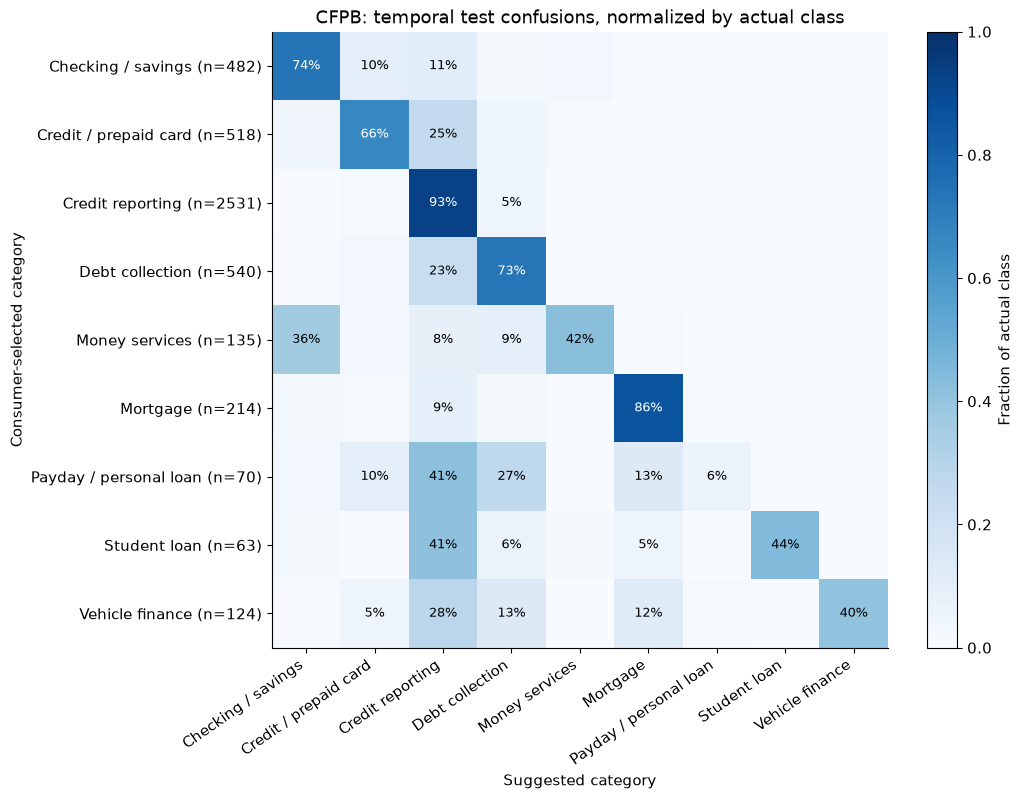

In [3]:
from IPython.display import Image, display
display(Image(filename=str(CASE / 'figures/confusion.png')))

## Interpretation and full recomputation

Selected logistic_tfidf on validation macro-F1. Novel temporal test n=4,677: accuracy 80.74%, macro-F1 0.632, majority accuracy 54.12%. Threshold 0.6 has 273 wrong accepted suggestions; 1,506 low-confidence novel cases require review. Overall sampled workflow: 3,171/8,218 suggestions accepted (38.59%); 5,047 assigned to review including withheld text repeats. The subgroup review reinforces the recommendation: human verification is required; aggregate accepted accuracy is not a per-class routing guarantee.

No automatic routing recommended: aggregate accepted accuracy hides weak true-class outcomes. Results are on a 3% ID sample and template-filtered cohort. Character matching is not semantic deduplication. Confidence/Wilson search does not give a post-selection probability guarantee. Private text and vocabulary excluded; human-verification workflow required.

From the portfolio root, use the environment and authorised inputs in `docs/REPRODUCIBILITY.md`, then execute `python src/cfpb_production.py`. Do not rerun the data audits merely to read these results. A standalone Kaggle environment requires adapting input mounting and installing the documented dependencies; no hosted execution is claimed.